In [23]:
import numpy as np
import matplotlib.pyplot as plt
import utils
import scipy
import sklearn

In [159]:
datasets = open("3d.txt").readlines()
datasets = [d.strip() for d in datasets]
datasets = [d for d in datasets if d != "RF00375"]
ss_files = [f"data/{d}/ss.txt" for d in datasets]
    

In [225]:
def p_values(scores):

    assert(scores == scores).all()
    
    
    L = utils.reverse_triangle_number(len(scores)) + 1

    # Remove L//2 highest scores, because they might be positive
    null_scores = np.partition(scores, -L//2)[:-L//2]


    fit = scipy.stats.exponnorm.fit(null_scores, method='mle')
    
    print(fit)

    p_vals = scipy.stats.exponnorm.logsf(scores, *fit)

    return p_vals

In [226]:
def pairs_from_secondary(input_string: str) -> list[tuple[int, int]]:
    """
        Will give a list of pairs of indices that are paired in the secondary structure.
        (i,j): i < j is garanteed
    """
    open_par = ['(', '[', '{', '<', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
    close_par = [')', ']', '}', '>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']

    stacks = {}  # Contains tuple with (is_open, stack)

    for open, close in zip(open_par, close_par):
        stacks[open] = (True, [])
        stacks[close] = (False, stacks[open][1])  # Points to the same stack

    result = []  # List to store pairs of matching indices

    for index, char in enumerate(input_string):
        if char in stacks:
            is_open, stack = stacks[char]
            if is_open:
                stack.append(index)
            else:
                open_index = stack.pop()
                result.append((open_index, index))

    assert (all([not bool(stack) for (_, stack) in stacks.values()]))

    return result

In [227]:
def collect(method):
    all_mask = []
    all_scores = []
    if method == "phylo_score":
        score_files = [f"data/{d}/reg0.5_mireg0.0_scoreoptdiff_corrAPC.npz" for d in datasets]
    elif method == "rscape":
        score_files = [f"data/{d}/rscape_GTp.npz" for d in datasets]
    for score, ss in zip(score_files, ss_files):
        scores = np.load(score)
        ss = open(ss, 'r').read().strip()
        true_pairs = pairs_from_secondary(ss)
        all_pairs = np.triu_indices(len(ss), k = 1)

        mask = [p in true_pairs for p in zip(all_pairs[0], all_pairs[1])]
        
        all_mask.extend(mask)
        if method == "phylo_score":
            all_scores.extend(-p_values(scores['corrected_scores']))
        elif method == "rscape":
            all_scores.extend(-scores['p_values'])
    return np.array(all_mask), np.array(all_scores)

In [228]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_pr_curves(mask1, scores1, mask2, scores2, label1='Model 1', label2='Model 2', ax=None, title='Precision-Recall Curves'):
    precision1, recall1, _ = precision_recall_curve(mask1, scores1)
    ap1 = average_precision_score(mask1, scores1)
    
    precision2, recall2, _ = precision_recall_curve(mask2, scores2)
    ap2 = average_precision_score(mask2, scores2)
    
    if ax is None:
        plt.figure(figsize=(8, 6))
        ax = plt.gca()
    
    ax.plot(recall1, precision1, 'b-', linewidth=2, label=f'{label1} (AP = {ap1:.3f})')
    ax.plot(recall2, precision2, 'r-', linewidth=2, label=f'{label2} (AP = {ap2:.3f})')
    
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    
    return ax, (ap1, ap2)

In [229]:
mask, scores = collect("rscape")
mask2, scores2 = collect("phylo_score")

(np.float64(1.0683045402722355), np.float64(-4.024040065390979), np.float64(2.7065536765259752))
(np.float64(1.116996860000702), np.float64(-7.330025993539955), np.float64(3.6226823330627935))
(np.float64(1.9065745096645599), np.float64(-3.9731569555840474), np.float64(1.6860763913395351))
(np.float64(1.2028465923966896), np.float64(-3.5739969926344717), np.float64(2.406114896956888))
(np.float64(2.49189431238153), np.float64(-4.396530649391261), np.float64(1.534654358811764))
(np.float64(1.4413969799884054), np.float64(-2.649779175794393), np.float64(1.7110156360667044))
(np.float64(1.9636698885576012), np.float64(-3.0483099672731333), np.float64(1.4826212997827968))
(np.float64(1.4770537542259965), np.float64(-3.680208801116073), np.float64(2.3381834354089612))
(np.float64(1.0623537231118647), np.float64(-2.9267841890480275), np.float64(2.316782681504971))
(np.float64(1.7657992161515161), np.float64(-3.413810489456548), np.float64(1.7602912537372688))
(np.float64(1.8499804180169002),

(<Axes: title={'center': 'Precision-Recall Curves for R-scape and PhyloScore'}, xlabel='Recall', ylabel='Precision'>,
 (0.6276977889481999, 0.6577636241106021))

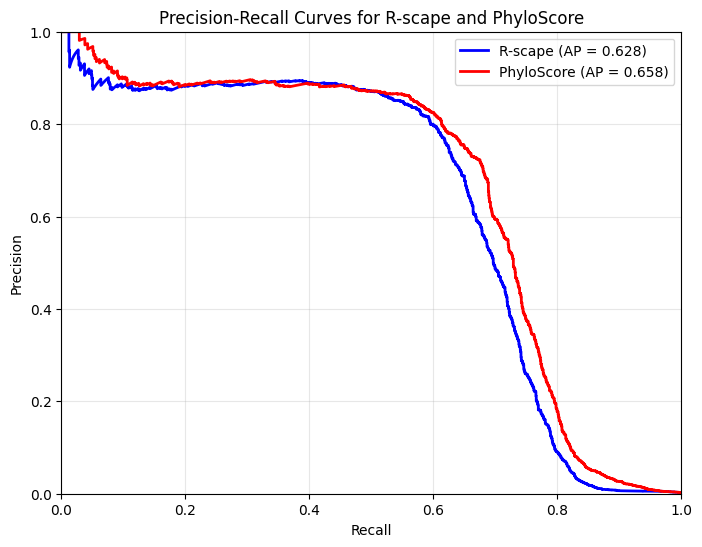

In [230]:
plot_pr_curves(mask, scores, mask2, scores2, label1='R-scape', label2='PhyloScore', title='Precision-Recall Curves for R-scape and PhyloScore')

In [ ]:
scores2.max()

np.float64(inf)